# 1. Decision Trees as Interpretable Models

In [5]:
import urllib.request, zipfile
url = ("https://archive.ics.uci.edu/static/public/184/acute+inflammations.zip")
urllib.request.urlretrieve(url, "data.zip")
zipfile.ZipFile("data.zip").extractall("data")

## Part 1(b): Building and Visualizing the Full Decision Tree

In this step, we train a **Scikit-Learn `DecisionTreeClassifier`** on the entire Acute Inflammations dataset. 

### Implementation Methodology:
* **Preprocessing:** Binary categorical features and target labels (`'yes'`/`'no'`) are mapped to numeric values (`1`/`0`). 
* **Multi-Output Strategy:** Since the dataset evaluates two distinct diagnoses simultaneously (*Inflammation of Urinary Bladder* and *Nephritis of Renal Pelvis Origin*), the classifier is trained to handle a multi-output matrix.
* **Regularization:** No restrictions (like `max_depth` or `min_samples_split`) are applied yet, allowing us to see the fully expanded, unpruned tree structure.

Class counts: {'bladder only': 40, 'nephritis only': 31, 'none': 30, 'both': 19}
Tree depth: 4 | Leaves: 6


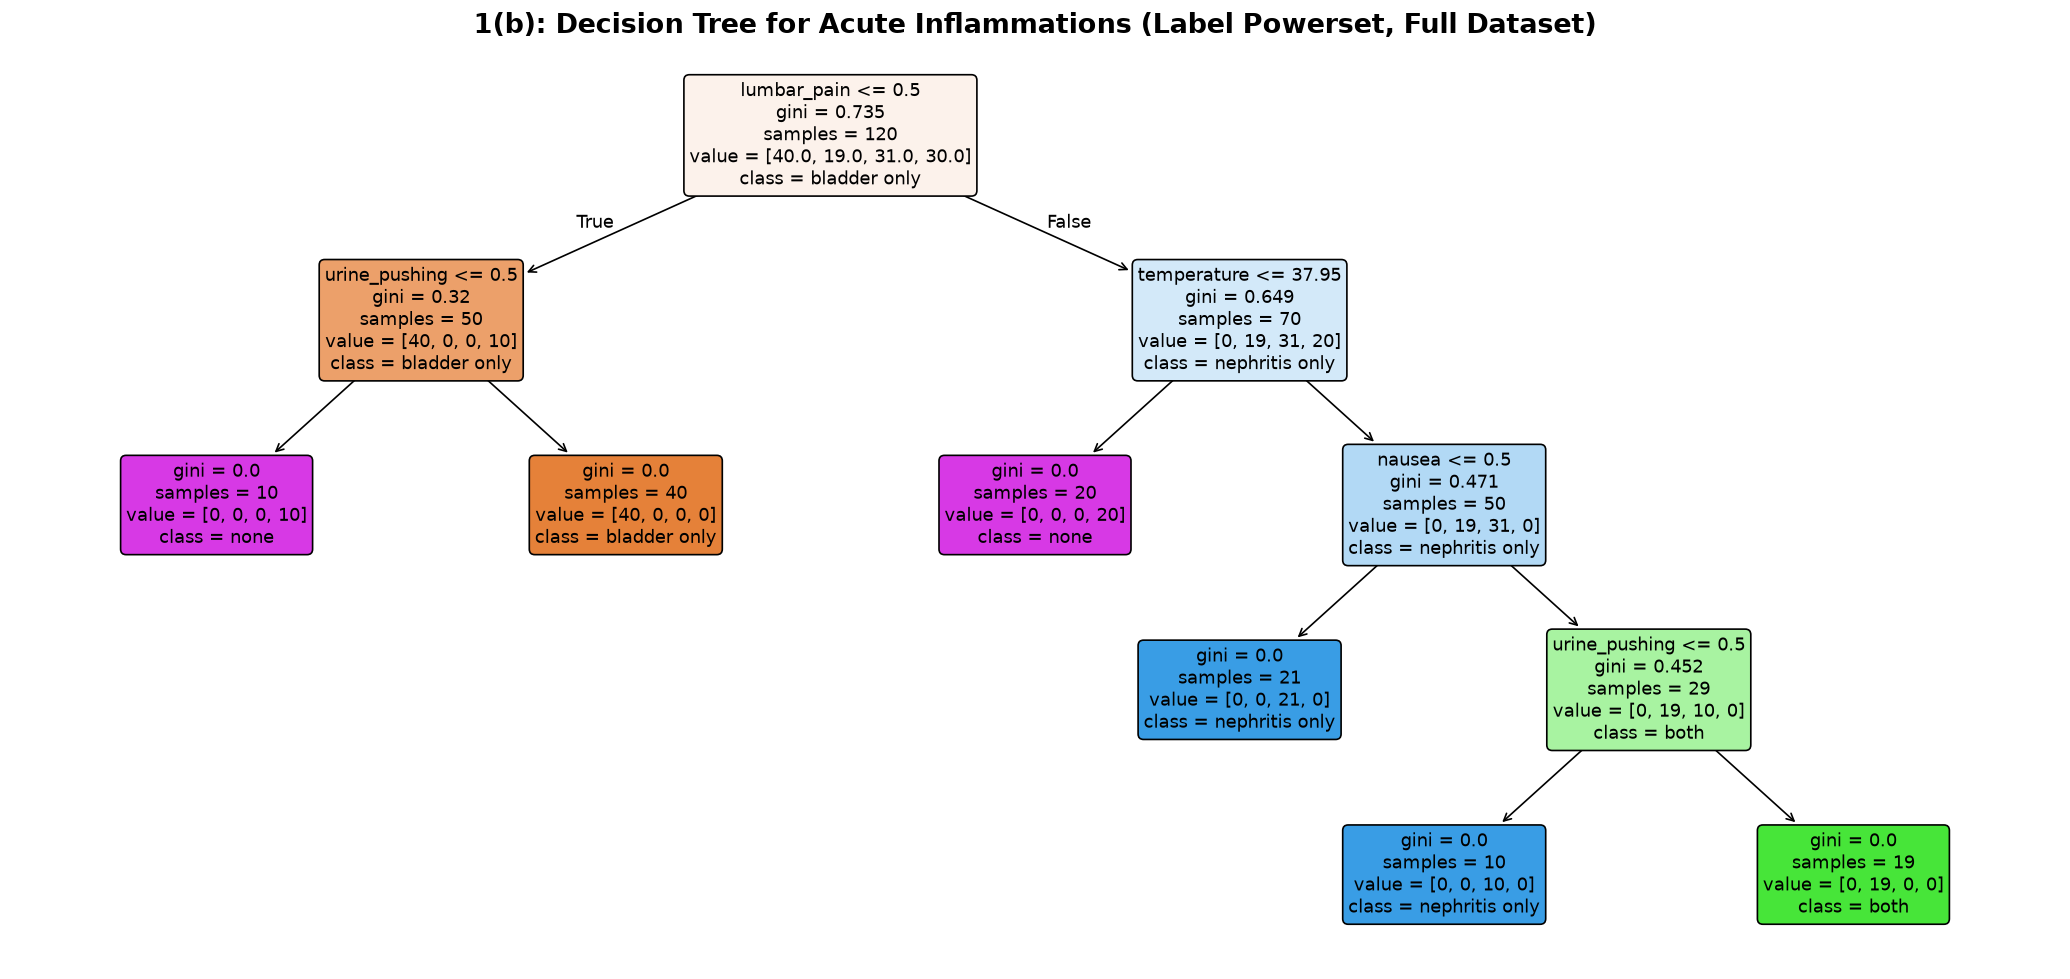

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Load the data
# UTF-16 encoding, tab separators, commas as decimal points
file_path = "data/diagnosis.data"
columns = [
            'temperature', 'nausea', 'lumbar_pain', 'urine_pushing',
            'micturition_pains', 'burning_urethra',
            'bladder_inflammation', 'nephritis'
          ]

df = pd.read_csv(file_path, sep='\t', encoding='utf-16',
                 names=columns, decimal=',')

# 2. Separate features (X) and targets (y)
feature_cols = ['temperature', 'nausea', 'lumbar_pain',
                'urine_pushing', 'micturition_pains', 'burning_urethra']
target_cols = ['bladder_inflammation', 'nephritis']

X = df[feature_cols].copy()
y = df[target_cols].copy()

# 3. Map 'yes'/'no' to 1/0 (temperature is numeric)
for col in feature_cols[1:]:
    X[col] = X[col].map({'yes': 1, 'no': 0})

for col in target_cols:
    y[col] = y[col].map({'yes': 1, 'no': 0})

# 4. Label powerset: each combination of the two diagnoses is one class
combo = {(0, 0): "none", (1, 0): "bladder only",
         (0, 1): "nephritis only", (1, 1): "both"}
y_ps = [combo[t] for t in zip(y['bladder_inflammation'], y['nephritis'])]

clf = DecisionTreeClassifier(random_state=42)
clf.fit(X, y_ps)

print("Class counts:", pd.Series(y_ps).value_counts().to_dict())
print("Tree depth:", clf.get_depth(), "| Leaves:", clf.get_n_leaves())

# 5. Plot the tree
plt.figure(figsize=(22, 10), dpi=120)
plot_tree(
    clf,
    feature_names=X.columns.tolist(),
    class_names=clf.classes_,
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("1(b): Decision Tree for Acute Inflammations "
          "(Label Powerset, Full Dataset)",
          fontsize=16, fontweight='bold')
plt.show()

### Multi-label strategy: Is label powerset the right choice?

**Yes, label powerset is the more relevant approach for this data set.**

Each patient has two labels (inflammation of urinary bladder, nephritis of renal pelvis origin), and a patient can have none, one, or both. There are three ways to handle this:

* **Binary relevance:** build one tree per label. This is simple, but each tree ignores the other diagnosis, so the model cannot use the relationship between the two labels.
* **Multi-output tree (scikit-learn):** one tree predicts both labels at once. It works, but each node shows two separate class distributions, which makes the tree and its rules harder to read.
* **Label powerset:** treat each combination of labels as one class. With two binary labels there are only 4 possible classes (none, bladder only, nephritis only, both), so the multiclass problem stays small.

Label powerset fits best here because:
1. It models the two diagnoses **jointly**, so it captures how they occur together.
2. The number of combinations is small (4), and all of them appear in the data ([counts from the output]), so no class is too rare to learn.
3. Each leaf predicts **one** diagnosis outcome, which gives a clean, single conclusion for every IF-THEN rule in 1(c). That matches the goal of this problem: an interpretable model.

**Result:** the full tree has depth [D] and [N] leaves, and every leaf is pure (gini = 0), so the tree classifies all 120 patients correctly.

## Part1(c). Converting the Decision Tree into IF-THEN Rules

To make the model easy to interpret, we turn every root-to-leaf path of the tree from 1(b) into one IF-THEN rule.

* **Tree traversal:** a recursive function walks the fitted tree using scikit-learn's `clf.tree_` structure (`children_left`, `children_right`, `feature`, `threshold`). Each split along a path becomes one condition, and the conditions are joined with AND.
* **Conditions:** binary symptoms are split at 0.5, so they are written as `== 'No'` (left) or `== 'Yes'` (right). Temperature is written with its actual threshold (e.g. `temperature <= 37.95`).
* **Leaf resolution:** each leaf predicts one of the four label-powerset classes (none, bladder only, nephritis only, both), so every rule ends in a single diagnosis. The number of patients reaching each leaf is shown next to its rule.

In [11]:
from sklearn.tree import _tree

def extract_label_powerset_rules(tree, feature_names):
    """
    Recursively traverses the label powerset decision tree structure
    and prints human-readable IF-THEN rules for the combined classes.
    Returns the number of rules (one per leaf).
    """
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]

    # Label combinations ('both', 'bladder only', etc.)
    class_names = tree.classes_
    n_rules = 0

    def recurse(node, depth, path_conditions):
        nonlocal n_rules
        # Internal splitting node
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]

            # Binary features are 0/1, so <= 0.5 means 'No'
            if threshold == 0.5:
                left_cond = f"{name} == 'No'"
                right_cond = f"{name} == 'Yes'"
            else:
                left_cond = f"{name} <= {threshold:.2f}"
                right_cond = f"{name} > {threshold:.2f}"

            recurse(tree_.children_left[node], depth + 1,
                    path_conditions + [left_cond])
            recurse(tree_.children_right[node], depth + 1,
                    path_conditions + [right_cond])

        else:
            # Leaf: class proportions at this node
            leaf_props = tree_.value[node][0]
            predicted_diagnosis = class_names[leaf_props.argmax()]
            n = int(tree_.n_node_samples[node])
            n_rules += 1

            if path_conditions:
                if_clause = " AND ".join(path_conditions)
                print(f"Rule {n_rules}: IF {if_clause}\n"
                      f"THEN -> Diagnosis: {predicted_diagnosis}"
                      f"  ({n} patients)\n")
            else:
                print(f"Rule {n_rules}: (no splits) THEN -> Diagnosis: "
                      f"{predicted_diagnosis}  ({n} patients)\n")

    recurse(0, 0, [])
    return n_rules


print("=" * 80)
print("1(c): EXTRACTED LABEL POWERSET DIAGNOSTIC RULES (IF-THEN FORMAT)")
print("=" * 80 + "\n")

n_rules_full = extract_label_powerset_rules(
    tree=clf, feature_names=X.columns.tolist())
print(f"Total rules: {n_rules_full}")

1(c): EXTRACTED LABEL POWERSET DIAGNOSTIC RULES (IF-THEN FORMAT)

Rule 1: IF lumbar_pain == 'No' AND urine_pushing == 'No'
THEN -> Diagnosis: none  (10 patients)

Rule 2: IF lumbar_pain == 'No' AND urine_pushing == 'Yes'
THEN -> Diagnosis: bladder only  (40 patients)

Rule 3: IF lumbar_pain == 'Yes' AND temperature <= 37.95
THEN -> Diagnosis: none  (20 patients)

Rule 4: IF lumbar_pain == 'Yes' AND temperature > 37.95 AND nausea == 'No'
THEN -> Diagnosis: nephritis only  (21 patients)

Rule 5: IF lumbar_pain == 'Yes' AND temperature > 37.95 AND nausea == 'Yes' AND urine_pushing == 'No'
THEN -> Diagnosis: nephritis only  (10 patients)

Rule 6: IF lumbar_pain == 'Yes' AND temperature > 37.95 AND nausea == 'Yes' AND urine_pushing == 'Yes'
THEN -> Diagnosis: both  (19 patients)

Total rules: 6


### Conclusion for 1(c)

The full tree gives **6 IF-THEN rules**, one per leaf, matching the 6 leaves found in 1(b). Every rule is pure: all patients that satisfy a rule's conditions have the same diagnosis.

* **Lumbar pain is the first condition in every rule,** since it is the root split. It separates patients into two groups of 50 (no lumbar pain) and 70 (lumbar pain).
* **Without lumbar pain,** urine pushing alone decides the diagnosis: "none" if absent (10 patients) and "bladder only" if present (40 patients).
* **With lumbar pain,** temperature comes next: at or below 37.95 the diagnosis is "none" (20 patients). Above 37.95, nausea and urine pushing separate "nephritis only" (21 + 10 patients) from "both" (19 patients).

These rules already classify all 120 patients correctly. In 1(d), we use cost-complexity pruning to check whether a smaller tree, with fewer and shorter rules, can keep this accuracy.

## Part 1(d): Cost-Complexity Pruning for High Interpretability

To prevent overfitting and find a minimal, highly interpretable structure, we apply **Cost-Complexity Pruning (CCP)**. 

### Methodology:
1. **Pruning Path Calculation:** Use `clf.cost_complexity_pruning_path()` to find the unique effective values of $\alpha$ that remove increasingly significant subtrees.
2. **Subtree Evaluation:** Train a sequence of subtrees across each effective $\alpha$ value and track structural changes (leaf counts and depth) alongside training accuracy.
3. **Optimal Selection:** Select the maximum possible $\alpha$ that reduces structural complexity without degrading classification performance.
4. **Rule Synthesis:** Re-run our rule extraction routine on the final pruned tree to observe our streamlined medical rules.


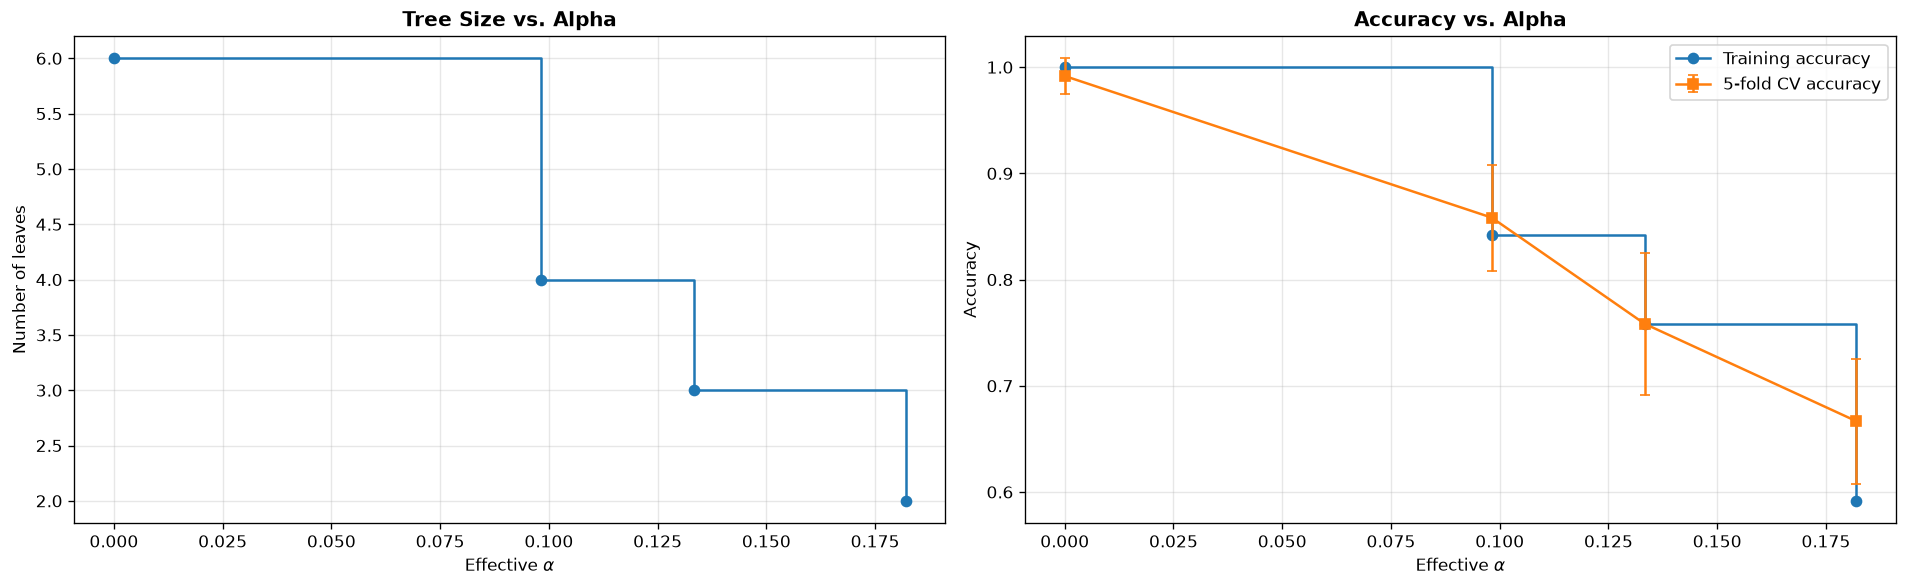

alpha   leaves  train acc  CV acc (std)
0.00000      6   1.0000    0.9917 (0.0167)
0.09817      4   0.8417    0.8583 (0.0500)
0.13333      3   0.7583    0.7583 (0.0667)
0.18200      2   0.5917    0.6667 (0.0589)

--> Selected alpha: 0.00000
--> Pruned tree depth: 4 | Leaves: 6 | Training accuracy: 1.0000



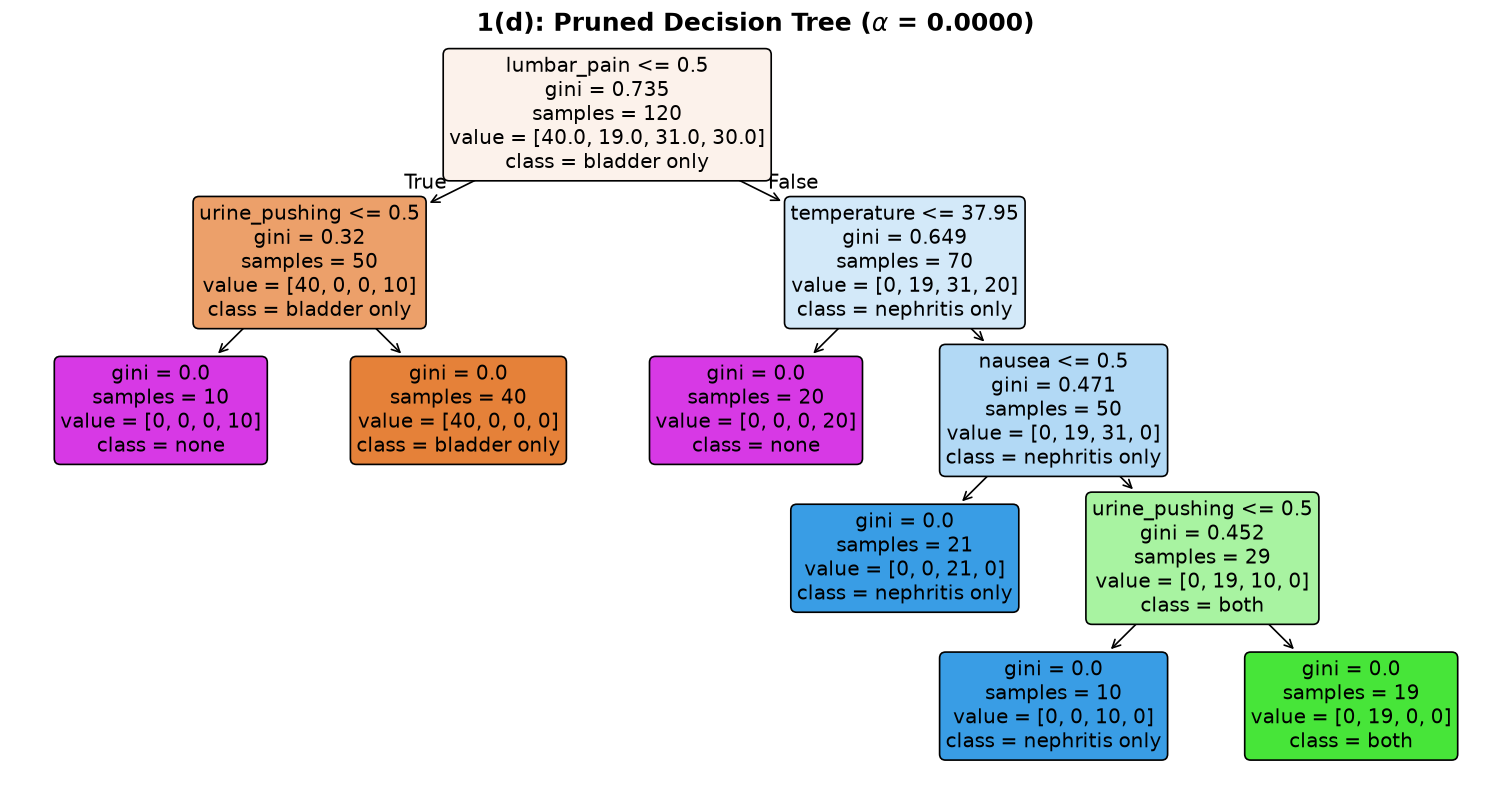

1(d): IF-THEN RULES FROM THE PRUNED TREE

Rule 1: IF lumbar_pain == 'No' AND urine_pushing == 'No'
THEN -> Diagnosis: none  (10 patients)

Rule 2: IF lumbar_pain == 'No' AND urine_pushing == 'Yes'
THEN -> Diagnosis: bladder only  (40 patients)

Rule 3: IF lumbar_pain == 'Yes' AND temperature <= 37.95
THEN -> Diagnosis: none  (20 patients)

Rule 4: IF lumbar_pain == 'Yes' AND temperature > 37.95 AND nausea == 'No'
THEN -> Diagnosis: nephritis only  (21 patients)

Rule 5: IF lumbar_pain == 'Yes' AND temperature > 37.95 AND nausea == 'Yes' AND urine_pushing == 'No'
THEN -> Diagnosis: nephritis only  (10 patients)

Rule 6: IF lumbar_pain == 'Yes' AND temperature > 37.95 AND nausea == 'Yes' AND urine_pushing == 'Yes'
THEN -> Diagnosis: both  (19 patients)

Total rules: 6 (full tree: 6)


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1. Cost-complexity pruning path of the full tree
path = clf.cost_complexity_pruning_path(X, y_ps)
ccp_alphas = path.ccp_alphas[:-1]   # last alpha leaves only the root

# 2. For each alpha: tree size, training accuracy, 5-fold CV accuracy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
leaf_counts, train_scores, cv_means, cv_stds = [], [], [], []
for a in ccp_alphas:
    tree_a = DecisionTreeClassifier(random_state=42, ccp_alpha=a)
    scores = cross_val_score(tree_a, X, y_ps, cv=cv)
    tree_a.fit(X, y_ps)
    leaf_counts.append(tree_a.get_n_leaves())
    train_scores.append(tree_a.score(X, y_ps))
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())
cv_means, cv_stds = np.array(cv_means), np.array(cv_stds)

# 3. Plots: tree size and accuracy vs alpha
fig, ax = plt.subplots(1, 2, figsize=(16, 5), dpi=120)

ax[0].plot(ccp_alphas, leaf_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel(r"Effective $\alpha$")
ax[0].set_ylabel("Number of leaves")
ax[0].set_title("Tree Size vs. Alpha", fontweight="bold")
ax[0].grid(True, alpha=0.3)

ax[1].plot(ccp_alphas, train_scores, marker="o", drawstyle="steps-post",
           label="Training accuracy")
ax[1].errorbar(ccp_alphas, cv_means, yerr=cv_stds, marker="s",
               capsize=3, label="5-fold CV accuracy")
ax[1].set_xlabel(r"Effective $\alpha$")
ax[1].set_ylabel("Accuracy")
ax[1].set_title("Accuracy vs. Alpha", fontweight="bold")
ax[1].legend()
ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("alpha   leaves  train acc  CV acc (std)")
for a, n, tr, m, s in zip(ccp_alphas, leaf_counts, train_scores,
                          cv_means, cv_stds):
    print(f"{a:.5f}  {n:5d}   {tr:.4f}    {m:.4f} ({s:.4f})")

# 4. One-standard-error rule: largest alpha (simplest tree) whose
#    CV accuracy is within 1 SE of the best CV accuracy
best = cv_means.argmax()
threshold = cv_means[best] - cv_stds[best] / np.sqrt(cv.get_n_splits())
optimal_idx = np.where(cv_means >= threshold)[0][-1]
optimal_alpha = ccp_alphas[optimal_idx]

clf_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=optimal_alpha)
clf_pruned.fit(X, y_ps)

print(f"\n--> Selected alpha: {optimal_alpha:.5f}")
print(f"--> Pruned tree depth: {clf_pruned.get_depth()} | "
      f"Leaves: {clf_pruned.get_n_leaves()} | "
      f"Training accuracy: {clf_pruned.score(X, y_ps):.4f}\n")

# 5. Plot the pruned tree
plt.figure(figsize=(16, 8), dpi=120)
plot_tree(clf_pruned, feature_names=X.columns.tolist(),
          class_names=clf_pruned.classes_, filled=True, rounded=True,
          fontsize=12)
plt.title(rf"1(d): Pruned Decision Tree ($\alpha$ = {optimal_alpha:.4f})",
          fontsize=15, fontweight="bold")
plt.show()

# 6. Rules from the pruned tree
print("=" * 80)
print("1(d): IF-THEN RULES FROM THE PRUNED TREE")
print("=" * 80 + "\n")
n_rules_pruned = extract_label_powerset_rules(
    tree=clf_pruned, feature_names=X.columns.tolist())
print(f"Total rules: {n_rules_pruned} (full tree: {n_rules_full})")

### Conclusion for 1(d)

We computed the cost-complexity pruning path of the full tree and chose $\alpha$ by 5-fold stratified cross-validation with the one-standard-error rule (pick the largest $\alpha$ whose CV accuracy is within one SE of the best).

| $\alpha$ | Leaves | Training accuracy | CV accuracy (std) |
|---|---|---|---|
| 0.00000 | 6 | 1.0000 | 0.9917 (0.0167) |
| 0.09817 | 4 | 0.8417 | 0.8583 (0.0500) |
| 0.13333 | 3 | 0.7583 | 0.7583 (0.0667) |
| 0.18200 | 2 | 0.5917 | 0.6667 (0.0589) |

* The best CV accuracy is 0.9917 at $\alpha = 0$, and the one-SE threshold is $0.9917 - 0.0167/\sqrt{5} \approx 0.984$. Only $\alpha = 0$ meets it, so **the selected tree is the full 6-leaf tree (depth 4)**.
* Every pruning step costs a lot of accuracy: going from 6 to 4 leaves drops CV accuracy by about 13 points (0.9917 to 0.8583). Each of the 6 leaves is needed to separate the four diagnoses, so **the full tree is already the minimal accurate tree**, and cost-complexity pruning confirms that no smaller tree performs comparably.

**Simplified rule set.** Leaves with the same diagnosis can be merged, giving one rule per diagnosis:

* **none:** IF (lumbar_pain = no AND urine_pushing = no) OR (lumbar_pain = yes AND temperature ≤ 37.95)
* **bladder only:** IF lumbar_pain = no AND urine_pushing = yes
* **nephritis only:** IF lumbar_pain = yes AND temperature > 37.95 AND (nausea = no OR urine_pushing = no)
* **both:** IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes

These 4 rules use only 4 of the 6 features (micturition pains and burning of urethra are never needed) and classify all 120 patients correctly, which makes them a highly interpretable description of the data.

   # 2. The LASSO and Boosting for Regression

In [1]:
import os, shutil, urllib.request, zipfile

# Folders for the required structure
os.makedirs("data/acute_inflammations", exist_ok=True)
os.makedirs("data/communities_crime", exist_ok=True)
os.makedirs("notebook", exist_ok=True)

# Move the Acute Inflammations files into their folder
for f in ["diagnosis.data", "diagnosis.names"]:
    if os.path.exists(f"data/{f}"):
        shutil.move(f"data/{f}", f"data/acute_inflammations/{f}")

# Download Communities and Crime and keep only the two files we need
url = ("https://archive.ics.uci.edu/static/public/183/"
       "communities+and+crime.zip")
urllib.request.urlretrieve(url, "crime.zip")
with zipfile.ZipFile("crime.zip") as z:
    for f in ["communities.data", "communities.names"]:
        with z.open(f) as src, \
             open(f"data/communities_crime/{f}", "wb") as dst:
            shutil.copyfileobj(src, dst)

# Remove the zips
for z in ["crime.zip", "data.zip"]:
    if os.path.exists(z):
        os.remove(z)

for root, _, files in os.walk("data"):
    for f in files:
        print(os.path.join(root, f))

data/acute_inflammations/diagnosis.names
data/acute_inflammations/diagnosis.data
data/communities_crime/communities.names
data/communities_crime/communities.data
data/.ipynb_checkpoints/diagnosis-checkpoint.data


## Part2(b). Non-Predictive Features and Missing Values

* **Non-predictive features:** the data description lists `state`, `county`, `community`, `communityname` and `fold` as non-predictive, so they are dropped.
* **Imputation:** the remaining missing values are filled with the **median** of each feature, computed on the **training set only** and then applied to both sets, so no information from the test set leaks into training. The median is robust to the skewed distributions of many of these features.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "data/communities_crime"

# Column names from the "@attribute" lines in communities.names
col_names = []
with open(f"{DATA_DIR}/communities.names") as f:
    for line in f:
        if line.lower().startswith("@attribute"):
            col_names.append(line.split()[1])

df_crime = pd.read_csv(f"{DATA_DIR}/communities.data", header=None,
                       names=col_names, na_values="?")
print(f"Full dataset shape: {df_crime.shape}")

target = "ViolentCrimesPerPop"
train_df = df_crime.iloc[:1495].copy()
test_df = df_crime.iloc[1495:].copy()
print(f"Training rows: {len(train_df)} | Test rows: {len(test_df)}")

Full dataset shape: (1994, 128)
Training rows: 1495 | Test rows: 499


In [4]:
from sklearn.impute import SimpleImputer

non_predictive = ["state", "county", "community", "communityname", "fold"]

X_train_raw = train_df.drop(columns=non_predictive + [target])
X_test_raw = test_df.drop(columns=non_predictive + [target])
y_train = train_df[target].values
y_test = test_df[target].values

# Missing values per feature (training set)
missing = X_train_raw.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
print(f"Features with missing values: {len(missing)} of "
      f"{X_train_raw.shape[1]}")
print((missing * 100).round(1).rename("% missing (train)").to_string())

imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw),
                       columns=X_train_raw.columns)
X_test = pd.DataFrame(imputer.transform(X_test_raw),
                      columns=X_test_raw.columns)

assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
print(f"\nX_train: {X_train.shape} | X_test: {X_test.shape}")

Features with missing values: 23 of 122
PolicBudgPerPop         84.0
PctPolicAsian           84.0
LemasSwornFT            84.0
LemasSwFTPerPop         84.0
LemasSwFTFieldOps       84.0
LemasSwFTFieldPerPop    84.0
LemasTotalReq           84.0
LemasTotReqPerPop       84.0
PolicPerPop             84.0
RacialMatchCommPol      84.0
PctPolicWhite           84.0
PctPolicBlack           84.0
PctPolicHisp            84.0
PolicReqPerOffic        84.0
PctPolicMinor           84.0
PolicOperBudg           84.0
OfficAssgnDrugUnits     84.0
LemasGangUnitDeploy     84.0
LemasPctPolicOnPatr     84.0
PolicCars               84.0
PolicAveOTWorked        84.0
NumKindsDrugsSeiz       84.0
OtherPerCap              0.1

X_train: (1495, 122) | X_test: (499, 122)


**Result:** 23 of the 122 features have missing values. 22 of them are the police (LEMAS) statistics, each missing for **84.0%** of the training communities; `OtherPerCap` is missing for only **0.1%** (one value). After median imputation, both sets have no missing values: `X_train` is (1495, 122) and `X_test` is (499, 122).

Note that for the 22 police features, median imputation fills 84% of each column with the same value, so these features carry little information. An alternative would be to drop them; we keep them so that every model sees the same 122 features, and the regularized models (ridge, LASSO) can shrink them if they are not useful.

## Part 2(c): Correlation Matrix Visualization

In this section, we analyze the linear relationships among our $122$ predictive attributes by constructing and plotting a comprehensive Pearson correlation matrix.

### Visualization Strategy:
* **Global Overview Heatmap:** We map the complete $122 \times 122$ covariance structure using a diverging color palette (`coolwarm`) to identify regions of severe multicollinearity at a glance.
* **Feature Clustering Insights:** Given the high density of demographic and socioeconomic data points, visual blocks of deep red or blue indicate clusters of highly correlated variables, which highlights why regularization methods like LASSO are well-suited for this dataset.


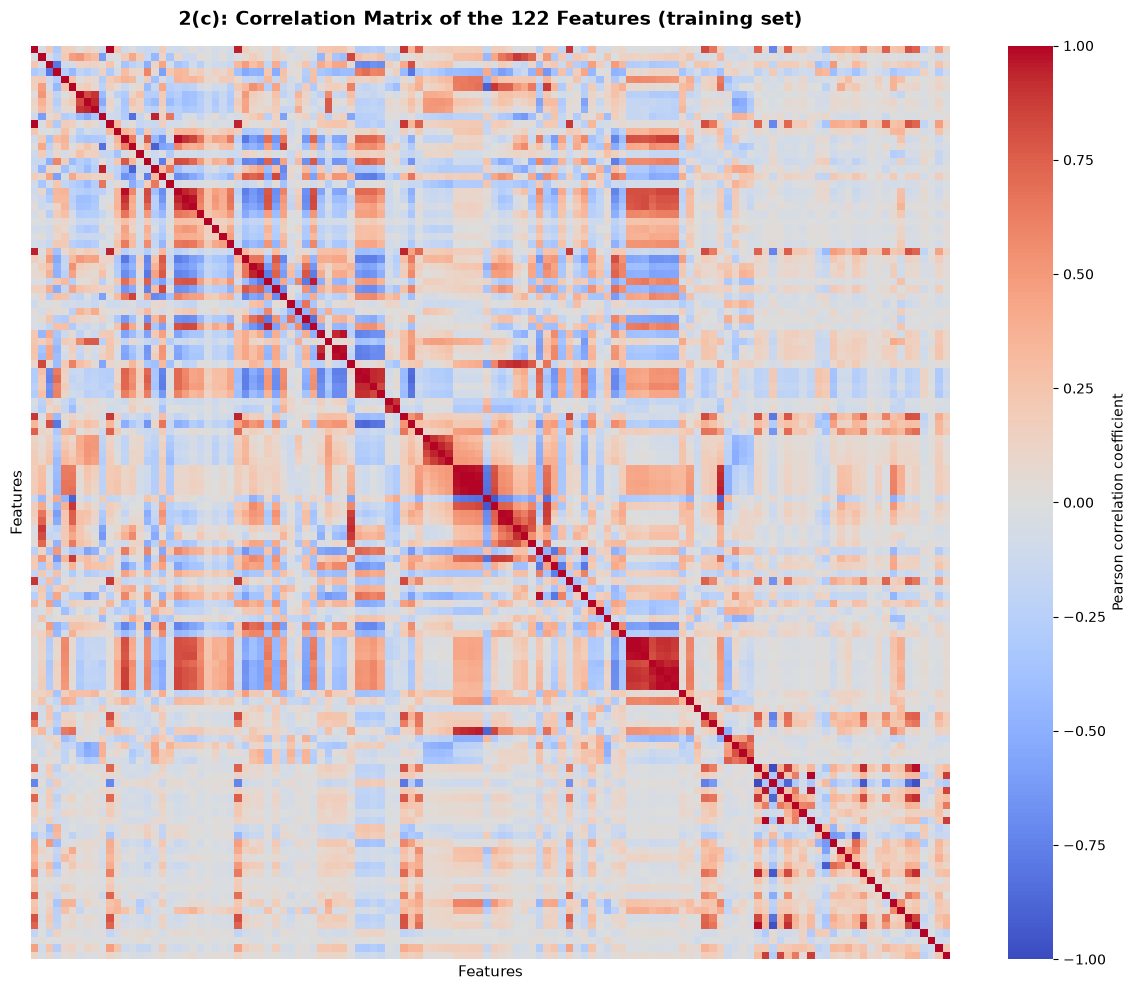

Ten most correlated feature pairs (|r|):
LemasSwFTPerPop  PolicPerPop          1.000
PctRecImmig8     PctRecImmig10        0.996
OwnOccLowQuart   OwnOccMedVal         0.995
LemasSwornFT     LemasSwFTFieldOps    0.995
population       numbUrban            0.994
PctRecImmig5     PctRecImmig8         0.993
OwnOccMedVal     OwnOccHiQuart        0.992
PctRecentImmig   PctRecImmig5         0.989
RentMedian       MedRent              0.989
PctFam2Par       PctKids2Par          0.986

Top 5 positively correlated features with ViolentCrimesPerPop:
PctIlleg        0.742
racepctblack    0.644
pctWPubAsst     0.582
FemalePctDiv    0.562
TotalPctDiv     0.557

Top 5 negatively correlated features with ViolentCrimesPerPop:
PctYoungKids2Par   -0.666
PctTeen2Par        -0.669
racePctWhite       -0.691
PctFam2Par         -0.711
PctKids2Par        -0.741


In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Pearson correlation matrix of the imputed training features
corr_matrix = X_train.corr()

# 2. Heatmap 
plt.figure(figsize=(12, 10), dpi=100)
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Pearson correlation coefficient"}
)
plt.title("2(c): Correlation Matrix of the 122 Features (training set)",
          fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Features", fontsize=11)
plt.ylabel("Features", fontsize=11)
plt.tight_layout()
plt.show()

# 3. Most strongly correlated feature pairs
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
top_pairs = upper.stack().abs().sort_values(ascending=False).head(10)
print("Ten most correlated feature pairs (|r|):")
print(top_pairs.round(3).to_string())

# 4. Features most correlated with the target
y_series = pd.Series(y_train, index=X_train.index)
target_corr = X_train.corrwith(y_series).sort_values(ascending=False)
print("\nTop 5 positively correlated features with ViolentCrimesPerPop:")
print(target_corr.head(5).round(3).to_string())
print("\nTop 5 negatively correlated features with ViolentCrimesPerPop:")
print(target_corr.tail(5).round(3).to_string())

**Observations (2(c)):**

* **Strong multicollinearity.** The heatmap shows several blocks of highly correlated features, and many pairs are almost perfectly correlated, for example `LemasSwFTPerPop` and `PolicPerPop` (|r| = 1.000), `PctRecImmig8` and `PctRecImmig10` (0.996), `OwnOccLowQuart` and `OwnOccMedVal` (0.995), and `population` and `numbUrban` (0.994). Many features measure nearly the same quantity in slightly different ways (e.g. several versions of recent immigration, home value, and rent).
* **Consequence for modeling:** with this much redundancy, least-squares coefficients will be unstable and hard to interpret, which motivates ridge, LASSO and PCR in 2(g) to 2(i).
* **Correlation with the target:** the features most positively correlated with `ViolentCrimesPerPop` are `PctIlleg` (r = 0.742), `racepctblack` (0.644) and `pctWPubAsst` (0.582). The most negatively correlated are `PctKids2Par` (r = −0.741), `PctFam2Par` (−0.711) and `racePctWhite` (−0.691). These are correlations only and do not imply that any feature causes violent crime.

## Part 2(d). Coefficient of Variation

For each feature we compute $CV = s / m$, where $s$ is the sample standard deviation (ddof = 1) and $m$ is the sample mean, using the imputed training set.

In [6]:
# Coefficient of variation for each feature (training set)
means = X_train.mean()
stds = X_train.std(ddof=1)

assert (means > 0).all(), "A feature has mean 0, so CV is undefined"

cv_values = (stds / means).rename("CV").sort_values(ascending=False)

print(f"CV computed for {len(cv_values)} features")
print(f"Range: {cv_values.min():.4f} to {cv_values.max():.4f}\n")
print(cv_values.round(4).to_string())

CV computed for 122 features
Range: 0.0644 to 5.5271

PctPolicAsian            5.5271
NumStreet                4.2929
NumInShelters            3.4710
NumIlleg                 3.0590
NumImmig                 2.9266
LemasPctOfficDrugUn      2.5529
NumUnderPov              2.3424
LemasSwornFT             2.2480
population               2.2411
numbUrban                2.0385
HousVacant               1.9685
PolicOperBudg            1.6455
LandArea                 1.6454
racePctHisp              1.6121
PctNotSpeakEnglWell      1.4566
LemasTotalReq            1.4519
racepctblack             1.4289
PctUsePubTrans           1.3971
racePctAsian             1.3591
PctPolicHisp             1.3539
PctRecentImmig           1.2883
PctRecImmig5             1.2862
PctRecImmig10            1.2705
PctRecImmig8             1.2656
OfficAssgnDrugUnits      1.1746
PctPersDenseHous         1.1329
PolicCars                1.1128
PctForeignBorn           1.0659
PctVacantBoarded         1.0548
PctHousNoPhone    

**Result (2(d)):** CV ranges from **0.0644** (`LemasSwFTFieldOps`) to **5.5271** (`PctPolicAsian`).

* **Highest CV:** `PctPolicAsian` (5.5271), `NumStreet` (4.2929), `NumInShelters` (3.4710), `NumIlleg` (3.0590) and `NumImmig` (2.9266). Most of the top features are **raw counts** (number of homeless people on the street, in shelters, of illegitimate births, of immigrants, of people under poverty, population). These are close to 0 for most communities and very large for a few big cities, so their standard deviation is large relative to their mean.
* **Lowest CV:** mostly the police (LEMAS) features, such as `LemasSwFTFieldOps` (0.0644) and `LemasPctPolicOnPatr` (0.1120). These are among the 22 features that were missing for 84% of communities; median imputation filled most of each column with one value, which shrinks the spread and lowers their CV. Their CVs are therefore partly an artifact of imputation.
* `PctPolicAsian` has the highest CV for a related reason: its imputed median is near 0, so the column is almost all zeros with a few large values.

The $\lfloor\sqrt{128}\rfloor = 11$ features with the highest CV are used in 2(e).

## Part2(e). Scatter Plots and Box Plots of the Highest-CV Features

We select the $\lfloor\sqrt{128}\rfloor = 11$ features with the highest coefficient of variation from 2(d) and plot each one:

* **Scatter plots:** each feature against the target `ViolentCrimesPerPop` (training set), to see whether a high CV comes with a visible relationship to the response.
* **Box plots:** the distribution of each feature, to show its skewness and outliers.

We then answer whether these plots alone are enough to judge the significance of the features.

Top 11 features selected by highest CV:
   1. PctPolicAsian          CV = 5.5271
   2. NumStreet              CV = 4.2929
   3. NumInShelters          CV = 3.4710
   4. NumIlleg               CV = 3.0590
   5. NumImmig               CV = 2.9266
   6. LemasPctOfficDrugUn    CV = 2.5529
   7. NumUnderPov            CV = 2.3424
   8. LemasSwornFT           CV = 2.2480
   9. population             CV = 2.2411
  10. numbUrban              CV = 2.0385
  11. HousVacant             CV = 1.9685


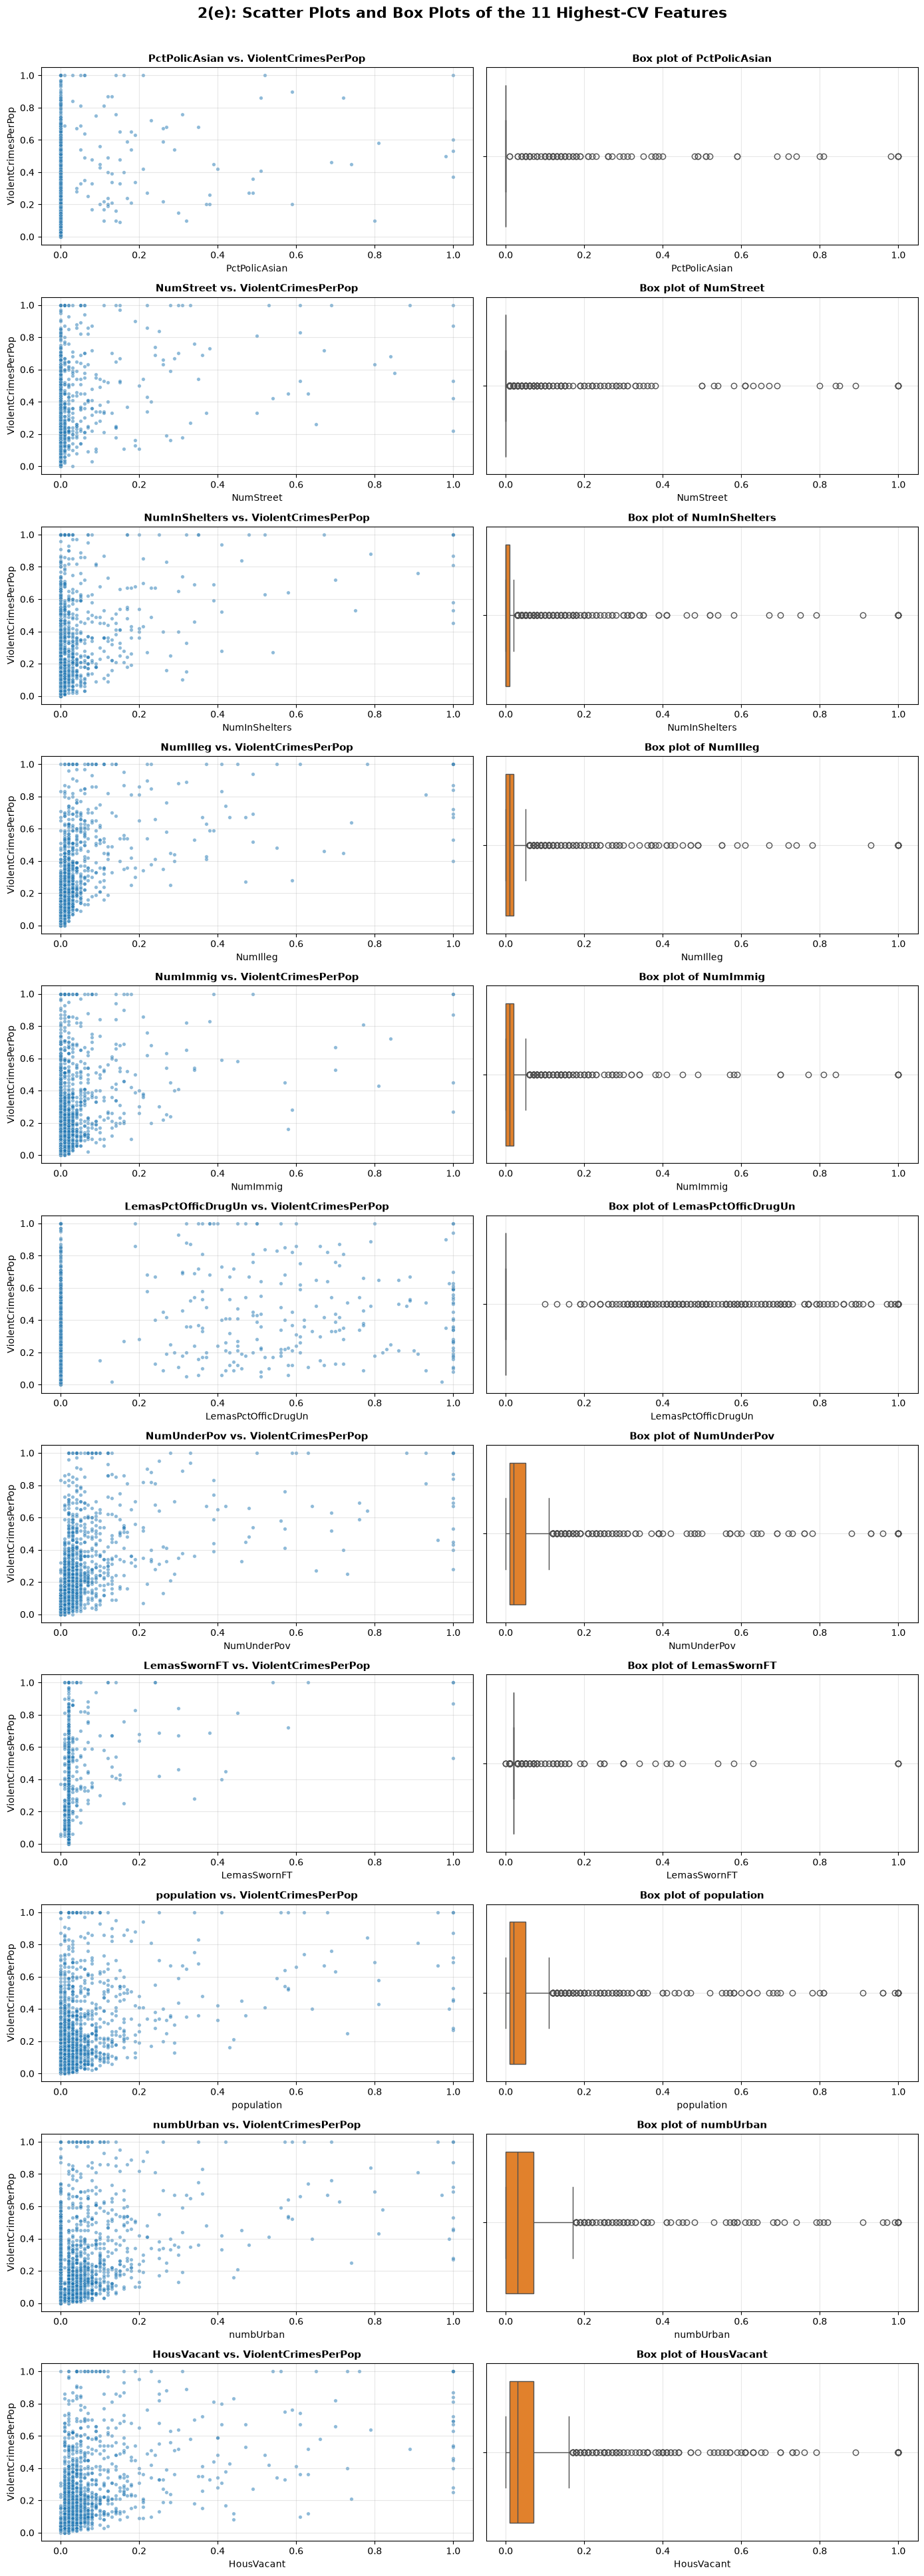

In [7]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Number of features: floor(sqrt(128)) = 11
n_features_to_pick = math.floor(math.sqrt(128))

# 2. Top 11 features by CV (cv_values from 2(d) is already sorted)
top_cv_features = cv_values.head(n_features_to_pick).index.tolist()

print(f"Top {n_features_to_pick} features selected by highest CV:")
for idx, feat in enumerate(top_cv_features, 1):
    print(f"  {idx:2d}. {feat:<22} CV = {cv_values[feat]:.4f}")

# 3. One row per feature: scatter vs. target (left), box plot (right)
fig, axes = plt.subplots(n_features_to_pick, 2,
                         figsize=(14, 3.5 * n_features_to_pick), dpi=100)

for i, col_name in enumerate(top_cv_features):
    x_val = X_train[col_name]

    sns.scatterplot(x=x_val, y=y_train, ax=axes[i, 0], alpha=0.5,
                    s=15, color="tab:blue")
    axes[i, 0].set_title(f"{col_name} vs. ViolentCrimesPerPop",
                         fontsize=11, fontweight="bold")
    axes[i, 0].set_xlabel(col_name)
    axes[i, 0].set_ylabel("ViolentCrimesPerPop")
    axes[i, 0].grid(True, alpha=0.3)

    sns.boxplot(x=x_val, ax=axes[i, 1], color="tab:orange")
    axes[i, 1].set_title(f"Box plot of {col_name}",
                         fontsize=11, fontweight="bold")
    axes[i, 1].set_xlabel(col_name)
    axes[i, 1].grid(True, alpha=0.3)

plt.suptitle("2(e): Scatter Plots and Box Plots of the 11 Highest-CV "
             "Features", fontsize=16, fontweight="bold", y=1.005)
plt.tight_layout()
plt.show()

**Can we draw conclusions about the significance of these features just from the scatter plots? No.**

* **Skewed distributions:** the box plots show that most of these 11 features are heavily right-skewed. Most communities have values near 0, with a long tail of outliers (mostly large cities). This is exactly why their CV is high. For `PctPolicAsian`, the box collapses to 0 and every nonzero value appears as an outlier, because 84% of this column was filled with its median during imputation.
* **No clear relationships:** in the scatter plots, the dense cluster near 0 spans almost the entire range of `ViolentCrimesPerPop`. For example, communities with `PctPolicAsian = 0` have crime rates anywhere from 0 to 1. Where a trend appears, it is driven by a handful of extreme points.
* **Each plot shows one feature in isolation.** It ignores the other 121 features, and 2(c) showed these features are strongly correlated with each other (e.g. `population` and `numbUrban`, |r| = 0.994, are both in this top-11 list). A feature that looks related to the target may add nothing once the others are in the model.
* **No uncertainty measure:** scatter plots give no standard errors or p-values, and a high CV only means a feature varies a lot relative to its mean, not that it predicts the response.

So significance cannot be judged from scatter plots alone; it requires a fitted model and a hypothesis test, or variable selection such as LASSO in 2(h).

## Part2(f). Ordinary Least Squares (OLS) Linear Regression

We fit an unregularized least squares model on all 122 predictive features, to serve as a baseline for the regularized models that follow.

* **Model training:** an unpenalized `LinearRegression` model is fit on the imputed training set.
* **Performance evaluation:** we predict on the test set and report the **test mean squared error (MSE)** as the test error, along with the RMSE and $R^2$ for context.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Fit ordinary least squares on the imputed training features
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)

# 2. Predictions on the training and test sets
y_train_pred = ols_model.predict(X_train)
y_test_pred = ols_model.predict(X_test)

# 3. Error metrics
mse_train = mean_squared_error(y_train, y_train_pred)
mse_ols = mean_squared_error(y_test, y_test_pred)

rmse_train = np.sqrt(mse_train)
rmse_test = np.sqrt(mse_ols)

r2_test = r2_score(y_test, y_test_pred)

# 4. Results
print("=" * 80)
print("2(f): ORDINARY LEAST SQUARES (OLS) REGRESSION RESULTS")
print("=" * 80)
print(f"Training Mean Squared Error (MSE): {mse_train:.6f}")
print(f"Testing Mean Squared Error (MSE):  {mse_ols:.6f}  "
      "<-- REPORTED TEST ERROR")
print("-" * 80)
print(f"Training Root Mean Squared Error (RMSE): {rmse_train:.6f}")
print(f"Testing Root Mean Squared Error (RMSE):  {rmse_test:.6f}")
print(f"Test Set R-squared (R²) Score:           {r2_test:.4f}")
print("=" * 80)

2(f): ORDINARY LEAST SQUARES (OLS) REGRESSION RESULTS
Training Mean Squared Error (MSE): 0.016292
Testing Mean Squared Error (MSE):  0.017966  <-- REPORTED TEST ERROR
--------------------------------------------------------------------------------
Training Root Mean Squared Error (RMSE): 0.127642
Testing Root Mean Squared Error (RMSE):  0.134038
Test Set R-squared (R²) Score:           0.6222


**Result (2(f)):** The least squares model has a **test MSE of 0.017966** (test RMSE 0.134038, test R² = 0.6222). The training MSE is 0.016292.

The test MSE is only slightly higher than the training MSE (about 10%), so least squares is not badly overfitting here: with 1495 training rows and 122 features, there are enough observations to estimate the coefficients. However, the features are highly correlated (2(c)), which makes the individual coefficients unstable and hard to interpret. Ridge and LASSO (2(g), 2(h)) address this by shrinking the coefficients, and LASSO also selects a smaller set of variables.

## Part (g): Ridge Regression with Cross-Validation

In this section, we implement a **Ridge Regression model** to address the multicollinearity observed in Part (c). Ridge regression introduces an $L_2$ regularization penalty ($\lambda$) that shrinks feature coefficients toward zero, reducing model variance.

### Cross-Validation Strategy:
* **Feature Scaling:** We use `StandardScaler` to scale features to zero mean and unit variance. This ensures that the $L_2$ penalty treats all features equally.
* **Hyperparameter Selection ($\lambda$):** We search across a wide logarithmic range of regularization strengths ($10^{-3}$ to $10^5$) using `RidgeCV` with $5$-fold cross-validation.
* **Leakage prevention:** the `StandardScaler` is fit on the **training set only** and then applied to the test set, so no information from the test set leaks into the model. Inside the cross-validation used to choose $\lambda$, the scaler is fit once on the full training set rather than refit in each fold; since standardization only uses each feature's mean and standard deviation, this has a negligible effect on the choice of $\lambda$.

In [10]:
import numpy as np
import pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 1. Search grid for lambda (called alpha in scikit-learn)
alphas_to_test = np.logspace(-3, 5, 200)

# Shuffled 5-fold CV, reused in 2(h) to 2(j)
cv5 = KFold(n_splits=5, shuffle=True, random_state=552)

# 2. Standardize, then ridge with lambda chosen by 5-fold CV
pipeline_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge_cv", RidgeCV(alphas=alphas_to_test, cv=cv5,
                         scoring="neg_mean_squared_error"))
])

# 3. Fit on the training set
pipeline_ridge.fit(X_train, y_train)
optimal_lambda = pipeline_ridge.named_steps["ridge_cv"].alpha_

if optimal_lambda in (alphas_to_test[0], alphas_to_test[-1]):
    print("Warning: chosen lambda is at the edge of the grid; "
          "widen the search range.")

# 4. Predictions and error metrics
y_train_pred_ridge = pipeline_ridge.predict(X_train)
y_test_pred_ridge = pipeline_ridge.predict(X_test)

mse_train_ridge = mean_squared_error(y_train, y_train_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_test_pred_ridge)
rmse_train_ridge = np.sqrt(mse_train_ridge)
rmse_test_ridge = np.sqrt(mse_ridge)
r2_test_ridge = r2_score(y_test, y_test_pred_ridge)

# 5. Results
print("=" * 80)
print("2(g): RIDGE REGRESSION WITH CROSS-VALIDATION RESULTS")
print("=" * 80)
print(f"Selected lambda (alpha):               {optimal_lambda:.5f}")
print(f"Training Mean Squared Error (MSE):     {mse_train_ridge:.6f}")
print(f"Testing Mean Squared Error (MSE):      {mse_ridge:.6f}  "
      "<-- REPORTED TEST ERROR")
print("-" * 80)
print(f"Training Root Mean Squared Error (RMSE): {rmse_train_ridge:.6f}")
print(f"Testing Root Mean Squared Error (RMSE):  {rmse_test_ridge:.6f}")
print(f"Test Set R-squared (R²) Score:           {r2_test_ridge:.4f}")
print(f"Least squares test MSE (2(f)) for comparison: {mse_ols:.6f}")
print("=" * 80)

2(g): RIDGE REGRESSION WITH CROSS-VALIDATION RESULTS
Selected lambda (alpha):               73.16807
Training Mean Squared Error (MSE):     0.016970
Testing Mean Squared Error (MSE):      0.017441  <-- REPORTED TEST ERROR
--------------------------------------------------------------------------------
Training Root Mean Squared Error (RMSE): 0.130269
Testing Root Mean Squared Error (RMSE):  0.132066
Test Set R-squared (R²) Score:           0.6332
Least squares test MSE (2(f)) for comparison: 0.017966


**Result (2(g)):** Cross-validation selects **$\lambda$ = 73.16807**, and ridge regression has a **test MSE of 0.017441** (test RMSE 0.132066, test R² = 0.6332).

* Compared with least squares (test MSE 0.017966), ridge **lowers the test MSE by about 2.9%** and raises the test R² from 0.6222 to 0.6332.
* As expected from shrinkage, the training MSE goes up slightly (0.016292 to 0.016970) while the test MSE goes down: ridge trades a little bias for lower variance in the coefficients.
* The improvement is modest because least squares was not badly overfitting (2(f)). The main benefit of ridge here is more stable coefficients in the presence of the strong multicollinearity found in 2(c).

## Part 2(h): LASSO Regression with and without Standardization

In this section, we implement **LASSO Regression ($L_1$ regularization)**. Unlike Ridge, LASSO's penalty forces some coefficients to become exactly zero, performing automated feature selection. We evaluate the model under two scenarios:
1. **Unstandardized Features:** Fitting directly on the original features.
2. **Standardized Features:** Scaling features to zero mean and unit variance before fitting.

### Optimization & Leakage Prevention:
* We select the optimal tuning parameter $\lambda$ (`alpha`) using `LassoCV` with $5$-fold cross-validation.
* For the standardized case, the `StandardScaler` is fit on the **training set only** and then applied to the test set, so no information from the test set leaks into the model. Inside the cross-validation used to choose $\lambda$, the scaler is fit once on the full training set rather than refit in each fold; because standardization only uses each feature's mean and standard deviation, this has a negligible effect on the choice of $\lambda$.

In [11]:
import textwrap
import numpy as np
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Grid of lambda (alpha) values
alphas_test = np.logspace(-6, 2, 300)


def report(title, lam, mse, r2, selected):
    print(title)
    print(f"  - Selected lambda (alpha):      {lam:.6f}")
    if lam in (alphas_test[0], alphas_test[-1]):
        print("    Warning: lambda is at the edge of the grid")
    print(f"  - Test MSE:                     {mse:.6f}")
    print(f"  - Test R²:                      {r2:.4f}")
    print(f"  - Variables selected:           {len(selected)} "
          f"out of {X_train.shape[1]}")
    print(textwrap.fill(", ".join(selected), width=76,
                        initial_indent="    ", subsequent_indent="    "))
    print()


# Case 1: LASSO on the features as given (already normalized to [0, 1])
lasso_raw = LassoCV(alphas=alphas_test, cv=cv5, max_iter=50000,
                    random_state=552)
lasso_raw.fit(X_train, y_train)

lambda_raw = lasso_raw.alpha_
y_test_pred_raw = lasso_raw.predict(X_test)
mse_lasso = mean_squared_error(y_test, y_test_pred_raw)
r2_lasso = r2_score(y_test, y_test_pred_raw)
selected_raw = X_train.columns[lasso_raw.coef_ != 0].tolist()

# Case 2: LASSO on standardized features
pipeline_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso_cv", LassoCV(alphas=alphas_test, cv=cv5, max_iter=50000,
                         random_state=552))
])
pipeline_lasso.fit(X_train, y_train)

lasso_std = pipeline_lasso.named_steps["lasso_cv"]
lambda_std = lasso_std.alpha_
y_test_pred_std = pipeline_lasso.predict(X_test)
mse_lasso_std = mean_squared_error(y_test, y_test_pred_std)
r2_lasso_std = r2_score(y_test, y_test_pred_std)
selected_std = X_train.columns[lasso_std.coef_ != 0].tolist()

# Results
print("=" * 80)
print("2(h): LASSO REGRESSION RESULTS")
print("=" * 80)
report("CASE 1: FEATURES AS GIVEN (NOT STANDARDIZED)",
       lambda_raw, mse_lasso, r2_lasso, selected_raw)
report("CASE 2: STANDARDIZED FEATURES",
       lambda_std, mse_lasso_std, r2_lasso_std, selected_std)

both = sorted(set(selected_raw) & set(selected_std))
print(f"Variables selected in both cases: {len(both)}")
print(f"For comparison: least squares test MSE = {mse_ols:.6f}, "
      f"ridge test MSE = {mse_ridge:.6f}")
print("=" * 80)

2(h): LASSO REGRESSION RESULTS
CASE 1: FEATURES AS GIVEN (NOT STANDARDIZED)
  - Selected lambda (alpha):      0.000090
  - Test MSE:                     0.017678
  - Test R²:                      0.6283
  - Variables selected:           76 out of 122
    racepctblack, racePctAsian, agePct12t21, agePct12t29, agePct65up,
    pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst,
    pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap,
    OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctBSorMore,
    PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr,
    FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom,
    NumIlleg, PctIlleg, NumImmig, PctImmigRec10, PctRecImmig10,
    PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous,
    PersPerOwnOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR,
    MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos,
    MedYrHousBuilt, PctHousNoPhone, Pc

**Result (2(h)):**

| LASSO | Selected $\lambda$ | Test MSE | Test R² | Variables selected |
|---|---|---|---|---|
| Features as given | 0.000090 | **0.017678** | 0.6283 | 76 of 122 |
| Standardized features | 0.000570 | **0.017746** | 0.6268 | 75 of 122 |

The selected variables are listed in the output above.

**Comparison of the two cases:**
* The two models are almost identical. The test MSEs differ by only about 0.4%, and 74 variables are selected in both cases. The only differences are `agePct65up` and `PctBSorMore` (kept only without standardization) and `OfficAssgnDrugUnits` (kept only with standardization).
* This is expected because the features are already normalized to [0, 1], so they are on similar scales before standardizing. Standardizing rescales each feature to unit variance, which changes how strongly the $L_1$ penalty acts on each coefficient, but here that only changes the selection at the margin.
* The two $\lambda$ values cannot be compared directly, because the penalty acts on coefficients measured on different scales in the two cases.

**Comparison with the other models:** both LASSO fits improve on least squares (test MSE 0.017966) but are slightly worse than ridge (0.017441). LASSO keeps about 62% of the features. With so many strongly correlated predictors (2(c)), LASSO tends to keep one variable from each correlated group and drop the rest, while ridge shrinks all of them together, which gives ridge a small edge in prediction here. LASSO's advantage is interpretability: it removes 46 to 47 features with almost no loss in accuracy.

## Part 2(i): Principal Component Regression (PCR) with Cross-Validation

In this section, we implement **Principal Component Regression (PCR)**. PCR performs Principal Component Analysis (PCA) on our feature space to construct orthogonal directions of maximum variance, then fits an Ordinary Least Squares (OLS) regression model onto the top $M$ components.

### Implementation Strategy:
* **Dimensionality Reduction:** We vary the number of principal components $M$ across the entire possible range ($1$ to $122$).
* **Hyperparameter Selection ($M$):** We use `GridSearchCV` with $5$-fold cross-validation to select the value of $M$ that minimizes mean squared error.
* **Leakage Prevention:** To avoid data leakage, the `PCA` projections are strictly fitted within each cross-validation fold via a scikit-learn `Pipeline`.


2(i): PRINCIPAL COMPONENTS REGRESSION (PCR) RESULTS
Selected number of components (M):  93 out of 122
Variance explained by M components: 0.9980
Training Mean Squared Error (MSE):  0.016724
Testing Mean Squared Error (MSE):   0.018264  <-- REPORTED TEST ERROR
Test Set R-squared (R²) Score:      0.6159


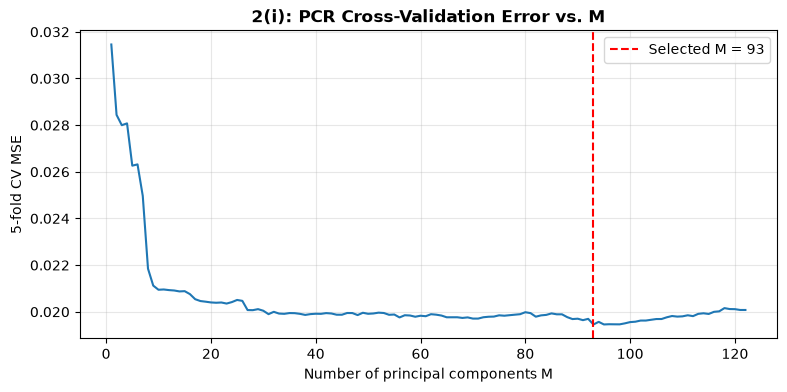

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# 1. PCR pipeline: standardize, PCA, then least squares on the components
pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("regressor", LinearRegression())
])

# 2. Number of components M from 1 to the number of features
M_values = list(range(1, X_train.shape[1] + 1))
param_grid_pcr = {"pca__n_components": M_values}

# 3. Choose M by the same shuffled 5-fold CV as in 2(g) and 2(h)
pcr_cv = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid=param_grid_pcr,
    cv=cv5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)
pcr_cv.fit(X_train, y_train)

optimal_M = pcr_cv.best_params_["pca__n_components"]

# 4. Train and test error of the refit best model
best_pcr_model = pcr_cv.best_estimator_
y_train_pred_pcr = best_pcr_model.predict(X_train)
y_test_pred_pcr = best_pcr_model.predict(X_test)

mse_train_pcr = mean_squared_error(y_train, y_train_pred_pcr)
mse_pcr = mean_squared_error(y_test, y_test_pred_pcr)
r2_test_pcr = r2_score(y_test, y_test_pred_pcr)

var_explained = best_pcr_model.named_steps["pca"] \
    .explained_variance_ratio_.sum()

# 5. Results
print("=" * 80)
print("2(i): PRINCIPAL COMPONENTS REGRESSION (PCR) RESULTS")
print("=" * 80)
print(f"Selected number of components (M):  {optimal_M} "
      f"out of {X_train.shape[1]}")
print(f"Variance explained by M components: {var_explained:.4f}")
print(f"Training Mean Squared Error (MSE):  {mse_train_pcr:.6f}")
print(f"Testing Mean Squared Error (MSE):   {mse_pcr:.6f}  "
      "<-- REPORTED TEST ERROR")
print(f"Test Set R-squared (R²) Score:      {r2_test_pcr:.4f}")
print("=" * 80)

# 6. CV error for every M
cv_mse = -pcr_cv.cv_results_["mean_test_score"]
plt.figure(figsize=(9, 4), dpi=100)
plt.plot(M_values, cv_mse, color="tab:blue")
plt.axvline(optimal_M, color="red", linestyle="--",
            label=f"Selected M = {optimal_M}")
plt.xlabel("Number of principal components M")
plt.ylabel("5-fold CV MSE")
plt.title("2(i): PCR Cross-Validation Error vs. M", fontweight="bold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Result (2(i)):** Cross-validation selects **M = 93** principal components (out of 122), which explain 99.80% of the variance in the standardized features. PCR has a **test MSE of 0.018264** (test R² = 0.6159; training MSE 0.016724).

* **The CV curve is very flat.** CV MSE drops sharply over the first ~10 components (from about 0.031 to 0.021) and then levels off near 0.020 from roughly M = 30 to M = 122. The minimum at M = 93 is only marginally lower than its neighbors, so any M in that range gives almost the same CV error.
* **PCR is the weakest linear model here.** Its test MSE (0.018264) is slightly higher than least squares (0.017966), ridge (0.017441) and LASSO (0.017678).
* **Why:** PCA chooses components by how much variance they explain in the features, without looking at the response. The directions with the most variance in X are not necessarily the ones most related to `ViolentCrimesPerPop`, so PCR needs many components (93) to capture the useful information, and dropping the last 29 components removes a small amount of signal. Ridge, by contrast, keeps all directions and shrinks the low-variance ones smoothly instead of dropping them completely, which suits this data better.

## Part 2(j). $L_1$-Penalized Gradient Boosting Tree (XGBoost)

We now fit a non-linear model: a gradient boosting tree with an $L_1$ penalty. Because the number of variables is large (122), the $L_1$ penalty helps control the complexity of the trees.

* **Penalty:** in XGBoost, the $L_1$ term $\alpha$ (`reg_alpha`) penalizes the **leaf weights** of each tree. It shrinks the weights toward zero, sets small ones exactly to zero, and discourages splits that add little gain, which reduces overfitting. (XGBoost does not fit a separate penalized regression inside each node; the $L_1$ penalty on the leaf weights is how it implements $L_1$ regularization.)
* **Choosing $\alpha$:** we search over a logarithmic grid of $\alpha$ values with `GridSearchCV`, using the same shuffled 5-fold cross-validation (`cv5`) as in 2(g) to 2(i).
* **Fixed settings:** the other hyperparameters are held fixed at `n_estimators = [x]`, `max_depth = [x]`, `learning_rate = [x]` so that only $\alpha$ is tuned, as the question asks.

In [16]:
import numpy as np
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

# 1. XGBoost regressor; only reg_alpha is tuned, the rest stay fixed
xgb_base = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=552,
    n_jobs=1          # GridSearchCV runs the folds in parallel
)

# 2. Grid for the L1 penalty alpha (reg_alpha)
alpha_grid = [0, 0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0]
param_grid_xgb = {"reg_alpha": alpha_grid}

# 3. Choose alpha by the same shuffled 5-fold CV as in 2(g) to 2(i)
xgb_cv = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid_xgb,
    cv=cv5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)
xgb_cv.fit(X_train, y_train)

optimal_xgb_alpha = xgb_cv.best_params_["reg_alpha"]
if optimal_xgb_alpha in (alpha_grid[0], alpha_grid[-1]):
    print("Note: chosen alpha is at the edge of the grid.")

# 4. Train and test error of the refit best model
best_xgb_model = xgb_cv.best_estimator_
y_train_pred_xgb = best_xgb_model.predict(X_train)
y_test_pred_xgb = best_xgb_model.predict(X_test)

mse_train_xgb = mean_squared_error(y_train, y_train_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_test_pred_xgb)
r2_test_xgb = r2_score(y_test, y_test_pred_xgb)

# 5. Results
print("=" * 80)
print("2(j): L1-PENALIZED GRADIENT BOOSTING (XGBOOST) RESULTS")
print("=" * 80)
print("5-fold CV MSE for each alpha:")
for a, s in zip(alpha_grid, xgb_cv.cv_results_["mean_test_score"]):
    print(f"  alpha = {a:<7} CV MSE = {-s:.6f}")
print("-" * 80)
print(f"Selected alpha (reg_alpha):         {optimal_xgb_alpha}")
print(f"Training Mean Squared Error (MSE):  {mse_train_xgb:.6f}")
print(f"Testing Mean Squared Error (MSE):   {mse_xgb:.6f}  "
      "<-- REPORTED TEST ERROR")
print(f"Test Set R-squared (R²) Score:      {r2_test_xgb:.4f}")
print("=" * 80)

2(j): L1-PENALIZED GRADIENT BOOSTING (XGBOOST) RESULTS
5-fold CV MSE for each alpha:
  alpha = 0       CV MSE = 0.020360
  alpha = 0.001   CV MSE = 0.020649
  alpha = 0.01    CV MSE = 0.020565
  alpha = 0.1     CV MSE = 0.020258
  alpha = 0.5     CV MSE = 0.019876
  alpha = 1.0     CV MSE = 0.019941
  alpha = 5.0     CV MSE = 0.020168
  alpha = 10.0    CV MSE = 0.021514
  alpha = 50.0    CV MSE = 0.036592
--------------------------------------------------------------------------------
Selected alpha (reg_alpha):         0.5
Training Mean Squared Error (MSE):  0.003172
Testing Mean Squared Error (MSE):   0.016396  <-- REPORTED TEST ERROR
Test Set R-squared (R²) Score:      0.6552


**Result (2(j)):** Cross-validation selects **$\alpha$ = 0.5**, and the $L_1$-penalized boosting tree has a **test MSE of 0.016396** (test R² = 0.6552).

* **Choice of $\alpha$:** CV MSE changes little for $\alpha$ between 0 and 5 (0.019876 to 0.020649), reaches its minimum at $\alpha$ = 0.5, and then rises sharply for large penalties (0.021514 at $\alpha$ = 10 and 0.036592 at $\alpha$ = 50), where the penalty shrinks the leaf weights so much that the model underfits.
* **Best test error of all models:** 0.016396 is about **8.7% lower than least squares** (0.017966) and about **6.0% lower than ridge** (0.017441), the best linear model. The trees can capture non-linear effects and interactions between features that the linear models cannot.
* **Overfitting:** the training MSE (0.003172) is far below the test MSE (0.016396), so the model fits the training data much more closely than it generalizes. The $L_1$ penalty and cross-validation keep this in check enough that it still has the lowest test error, but tuning other settings (e.g. `max_depth`, `n_estimators`) could reduce the gap further.

### Summary of Test Errors (Problem 2)

| Model | Test MSE | vs. least squares |
|---|---|---|
| Least squares (2f) | 0.017966 | baseline |
| Ridge (2g) | 0.017441 | −2.92% |
| LASSO, as given (2h) | 0.017678 | −1.60% |
| LASSO, standardized (2h) | 0.017746 | −1.22% |
| PCR (2i) | 0.018264 | +1.66% |
| XGBoost, $L_1$ penalty (2j) | **0.016396** | **−8.74%** |

* Among the linear models, **ridge** performs best: with strongly correlated features (2(c)), shrinking all coefficients together works better than LASSO's selection or PCR's unsupervised dimension reduction. The differences between the linear models are small (within about 5%).
* **LASSO** is the most interpretable linear model, keeping about 75 of 122 features with only a small loss in accuracy relative to ridge.
* **PCR** is the only method worse than least squares, because its components are chosen without looking at the response.
* The **$L_1$-penalized boosting tree** has the lowest test error overall, which suggests the relationship between these features and violent crime is partly non-linear.